# Modelled passive dye versus observed SF₆

This notebook compares the passive dye tracer simulated in the ROMS Iceland2 run (`/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/`, hourly history files `Iceland2_MARBL_2024_his.202407*.nc` on the grid `P_INPUT/Iceland2_grid.nc`) with the SF₆ observations in `../data/20241119_combined_data.xlsx`, where SF₆ served as a passive-tracer analogue. The model dye is scaled to SF₆ concentration, averaged over vertical levels `s_rho` 50–58 and the sampling hours of each observation day, and sampled at the observed positions. The notebook produces daily maps of the sampled model dye and a two-panel plot of bin-averaged modelled SF₆ against longitude with the daily weighted median longitude (panel b), the model counterpart of panel a in `sf6_observations.ipynb`.

## Setup

Imports the Python packages used below, Cartopy for the maps, and the `roms_regrid` helper from `roms_regrid.py` in this directory, which bilinearly interpolates ROMS rho-point fields to a regular longitude–latitude grid with xESMF.

In [3]:
# SF₆ / dye model comparison


import subprocess
import os
import pandas as pd
import netCDF4
import numpy as np
import glob
import time
import matplotlib.pyplot as plt
import copy
import xarray as xr
from datetime import datetime, timedelta 
import dask
from scipy.interpolate import griddata
#from ocean_c_lab_tools import *
#from celluloid import Camera 
#import PyCO2SYS as csys
import seawater as sw
import sys
import os

# Add parent directory to Python path
sys.path.append(os.path.abspath(".."))
from roms_regrid import *
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


## SF₆ observations

Reads the sheet `20241119_combined_data` of `../data/20241119_combined_data.xlsx`, converts it to an `xarray.Dataset` with dimensions `Date` and `Obs_no`, and collects the observed latitude and longitude (0–360 °E) for each date in `locations_array`, which is used below to sample the model. `max_sf` is the maximum observed SF₆ on the second date.

In [4]:
xls = pd.ExcelFile('../data/20241119_combined_data.xlsx')


combo = pd.read_excel(xls, '20241119_combined_data',decimal='.')
combo


,Date,Lat,Long,TIMESTAMP,Unnamed: 4,SF6 (fmol/L),Col,Area,TSG_salinity,TSG-temp,Obs_no
0,2024-07-17,64.32825,-21.80205,04:45:00,PM,0.10,R,0.1,33.3366,11.8161,1
1,2024-07-17,64.32976,-21.79768,04:46:00,PM,0.10,L,0.1,33.3808,11.6866,2
2,2024-07-17,64.33173,-21.79222,04:48:00,PM,0.10,R,0.1,33.3917,11.7163,3
3,2024-07-17,64.33325,-21.78762,04:49:00,PM,0.10,L,0.1,33.2175,11.8738,4
4,2024-07-17,64.33526,-21.78227,04:50:00,PM,0.10,R,0.1,33.1928,11.8925,5
...,...,...,...,...,...,...,...,...,...,...,...
2724,2024-07-25,64.29511,-22.05250,06:02:00,PM,3.58,L,1516.6,34.1858,12.9878,2725
2725,2024-07-25,64.29914,-22.06086,06:04:00,PM,6.28,L,2637.9,34.1605,12.9207,2726
2726,2024-07-25,64.30427,-22.06558,06:07:00,PM,4.64,L,1965.5,34.1565,12.9650,2727
2727,2024-07-25,64.30935,-22.07066,06:09:00,PM,4.46,L,1848.6,33.8809,12.9910,2728


In [5]:
obs=xr.Dataset.from_dataframe(combo)
obs=obs.set_index(index=['Date','Obs_no'])
#obs=obs.drop_duplicates('index')
obs=obs.unstack('index')
#obs=obs.rename(name_dict={'mon/day/yr':'time','Depth':'depth','Latitude(¬∞N)':'lat','Longitude(¬∞E)':'lon'})


In [6]:
import numpy as np

def get_daily_locations(obs_ds):
    dates = obs_ds['Date'].values
    num_days = len(dates)
    num_obs = obs_ds.dims['Obs_no']
    
    # Initialize empty array: (days, obs, 2)
    locations = np.empty((num_days, num_obs, 2))
    
    for i in range(0,num_days):
        lat = obs_ds['Lat'].isel(Date=i).values
        lon = obs_ds['Long'].isel(Date=i).values + 360  # convert to 0–360 range
        locations[i, :, 0] = lat
        locations[i, :, 1] = lon
    
    return locations

# Example usage
locations_array = get_daily_locations(obs)
print("Shape of locations array:", locations_array.shape)  # should be (9, 2729, 2)


Shape of locations array: (9, 2729, 2)


/tmp/ipykernel_1795737/1794326622.py:6: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  num_obs = obs_ds.dims['Obs_no']


In [7]:
max_sf=np.max(obs['SF6 (fmol/L)'].isel(Date=1))


## Model dye output and scaling

Opens the first Iceland2 history file and the model grid, averages the dye over levels `s_rho` 50–58 and the first 24 time steps, and regrids the dye and the land mask (`mask_rho`) to longitude–latitude. The next cell opens all July 2024 history files and sets `scaling_factor` to a fixed target maximum of 29293.88 divided by the maximum model dye. Day index and hour of day are then derived from `ocean_time` to select the model hours of each observation day.

In [9]:
#x=xr.open_mfdataset('/pscratch/sd/u/uheede/from_expanse/Iceland3/*', combine='nested', concat_dim=["time"])
# open dataset
x=xr.open_mfdataset('/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/Iceland2_MARBL_2024_his.20240717130000.nc', combine='nested', concat_dim=["time"])

# open grid
grid=xr.open_mfdataset('/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/P_INPUT/Iceland2_grid.nc')

x_mean=x.isel(s_rho=slice(50,59)).mean('s_rho').isel(time=slice(0,24)).mean('time')

dye=x_mean['dye']


# regridding
dye=roms_regrid(grid,dye)

mask=roms_regrid(grid,grid['mask_rho'])
#t=t.where(t != 0)
#s=s.where(s != 0)
;


/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)


''

In [10]:
import xarray as xr
import numpy as np

# Open dataset
x = xr.open_mfdataset(
    '/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/Iceland2_MARBL_2024_his.202407????????.nc',
    combine='nested',
    concat_dim=["time"]
)

# Compute global max of dye (ignoring NaNs)
dye_max = (
    x['dye']
    .max(dim=['time', 's_rho', 'eta_rho', 'xi_rho'], skipna=True)
    .compute()
    .item()
)

target_max = 29293.88

scaling_factor = target_max / dye_max
#scaling_factor=97.09
print(f"Current max dye: {dye_max:.6f}")
print(f"Scaling factor: {scaling_factor:.6f}")


Current max dye: 100.000000
Scaling factor: 292.938800


In [11]:
dye.load()
;


''

In [12]:
import numpy as np

# seconds since reference
ot = x['ocean_time']

# hour of day [0–23]
hour_of_day = ((ot % 86400) // 3600).astype(int)

# day index starting at 0
day_index = (ot // 86400).astype(int)


## Daily maps of model dye at the observation positions

For each day the dye is averaged over levels `s_rho` 50–58 and the model hours 17–19 (day 1) or 09–18 (later days), regridded, taken at the grid point nearest to each observed position and multiplied by `scaling_factor`. The maps use the same logarithmic colour scale (0.1 to 5 × 10⁴) as the observation maps in `sf6_observations.ipynb`. The first cell stacks nine days in one column; the second arranges them on a 3 × 3 grid and sets `scaling_factor = 1600` instead of the value computed above.

/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve t

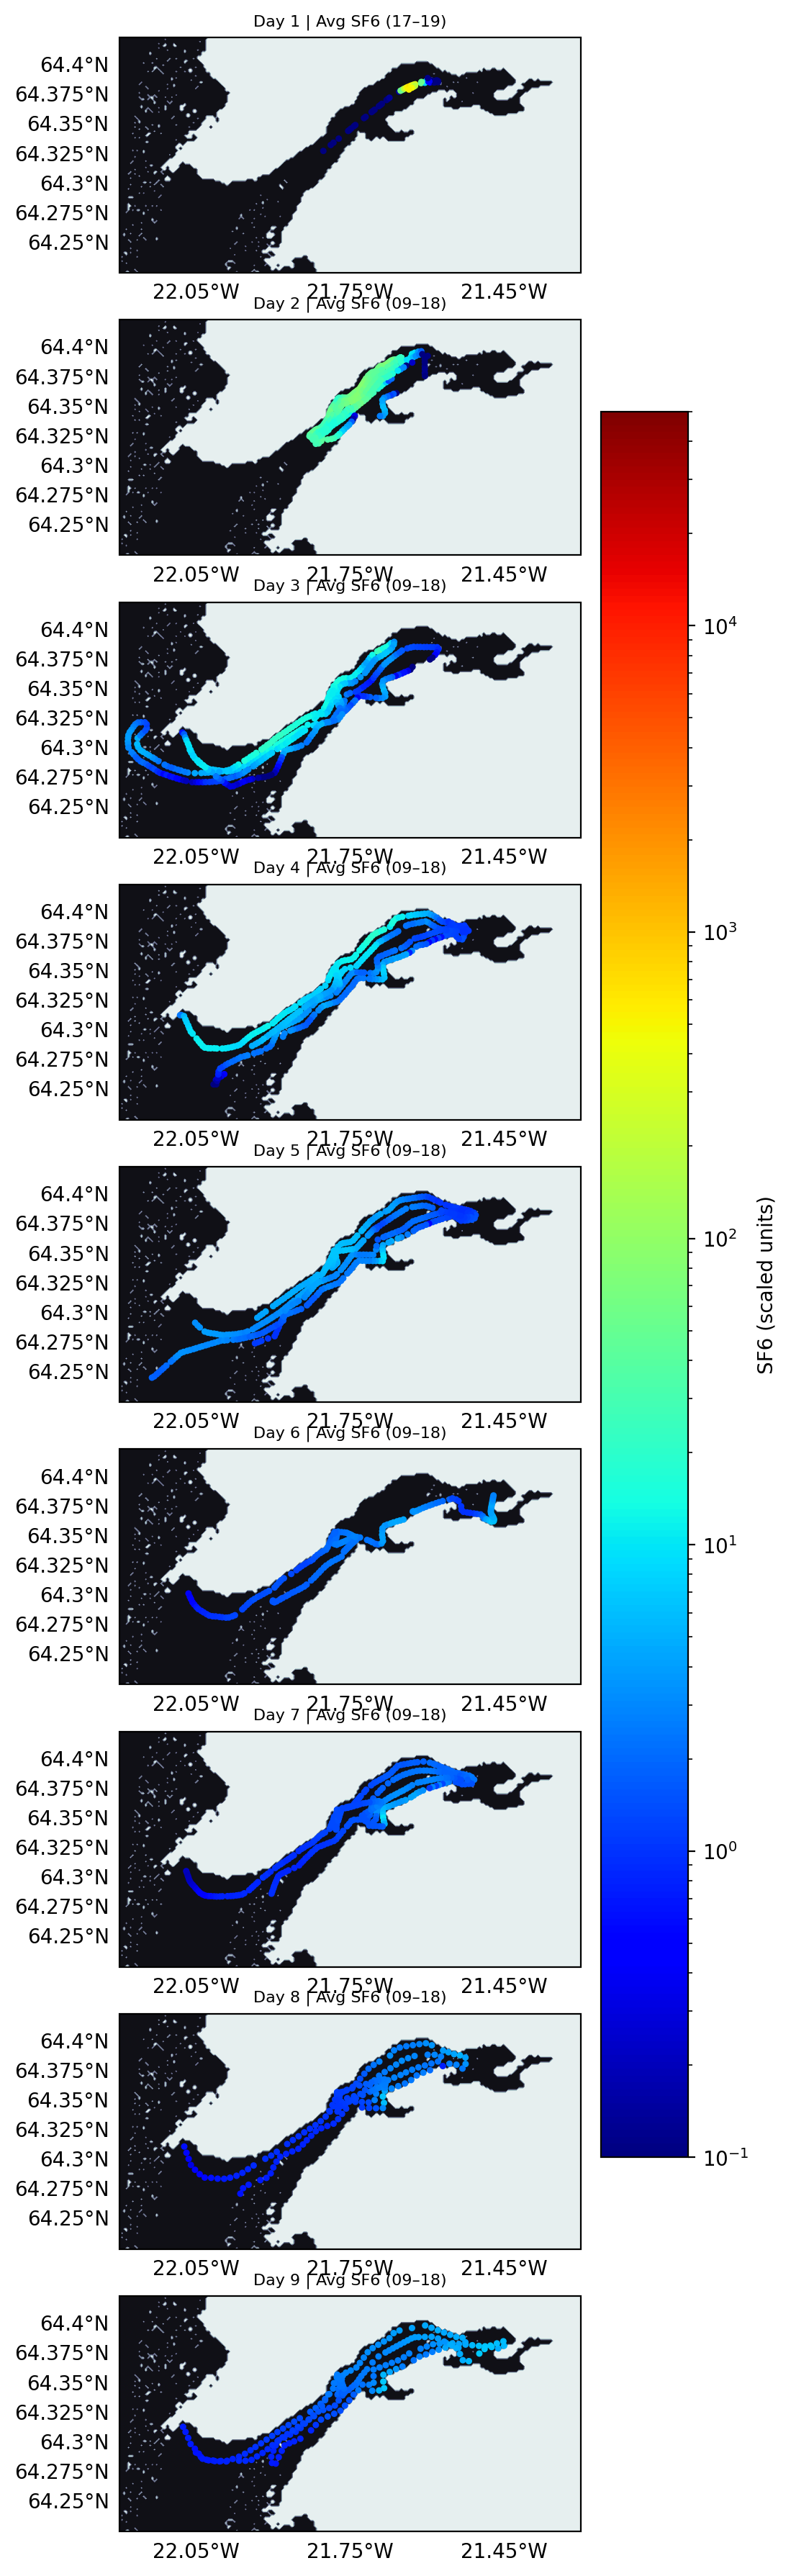

In [13]:
from matplotlib.colors import LogNorm
unique_days = np.unique(day_index.values)
num_days = 9
vmin, vmax = 1e-1, 5e4

fig, axs = plt.subplots(
    nrows=num_days,
    figsize=(6, 2.5 * num_days),
    dpi=200,
    subplot_kw={'projection': ccrs.Mercator()}
)

for d, day in enumerate(unique_days[:num_days]):

    day_mask = (day_index == day)

    if d == 0:
        hour_mask = (hour_of_day >= 17) & (hour_of_day < 19)
        title_hours = "17–19"
    else:
        hour_mask = (hour_of_day >= 9) & (hour_of_day < 18)
        title_hours = "09–18"

    time_mask = day_mask & hour_mask
    time_idx = np.where(time_mask.values)[0]

    if len(time_idx) == 0:
        continue

    x_day = (
        x
        .isel(time=time_idx)
        .isel(s_rho=slice(50, 59))
        .mean(dim=['time', 's_rho'])
    )
    dye = roms_regrid(grid, x_day['dye']).load()

    # -----------------------
    # Extract dye at locations
    # -----------------------
    dye_values, lats, lons = [], [], []

    clean_locs = locations_array[d, :, :]
    locations = clean_locs[~np.isnan(clean_locs).any(axis=1)]

    for lat, lon in locations:
        val = (
            dye
            .sel(lat=lat, method='nearest')
            .sel(lon=lon, method='nearest')
            .values
            * scaling_factor
        )
        dye_values.append(val)
        lats.append(lat)
        lons.append(lon)

    ax = axs[d]

    ax.contourf(
        mask.lon, mask.lat, mask.load(),
        transform=ccrs.PlateCarree(),
        cmap='bone_r'
    )

    sc = ax.scatter(
        lons, lats,
        c=dye_values,
        cmap='jet',
        s=5,
        norm=LogNorm(vmin=vmin, vmax=vmax),
        transform=ccrs.PlateCarree()
    )
    ax.set_extent(
        [-22.2, -21.3, 64.225, 64.424],  # [lon_min, lon_max, lat_min, lat_max]
        crs=ccrs.PlateCarree()
)
            # Add gridlines
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                        linewidth=1, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlines = False
    gl.ylines = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

  
    ax.set_title(f"Day {d+1} | Avg SF6 ({title_hours})", fontsize=8)

        # Shared colorbar for all days
cbar = fig.colorbar(
sc,
ax=axs,
orientation='vertical',
shrink=0.7,
pad=0.03
)
cbar.set_label('SF6 (scaled units)')


/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve t

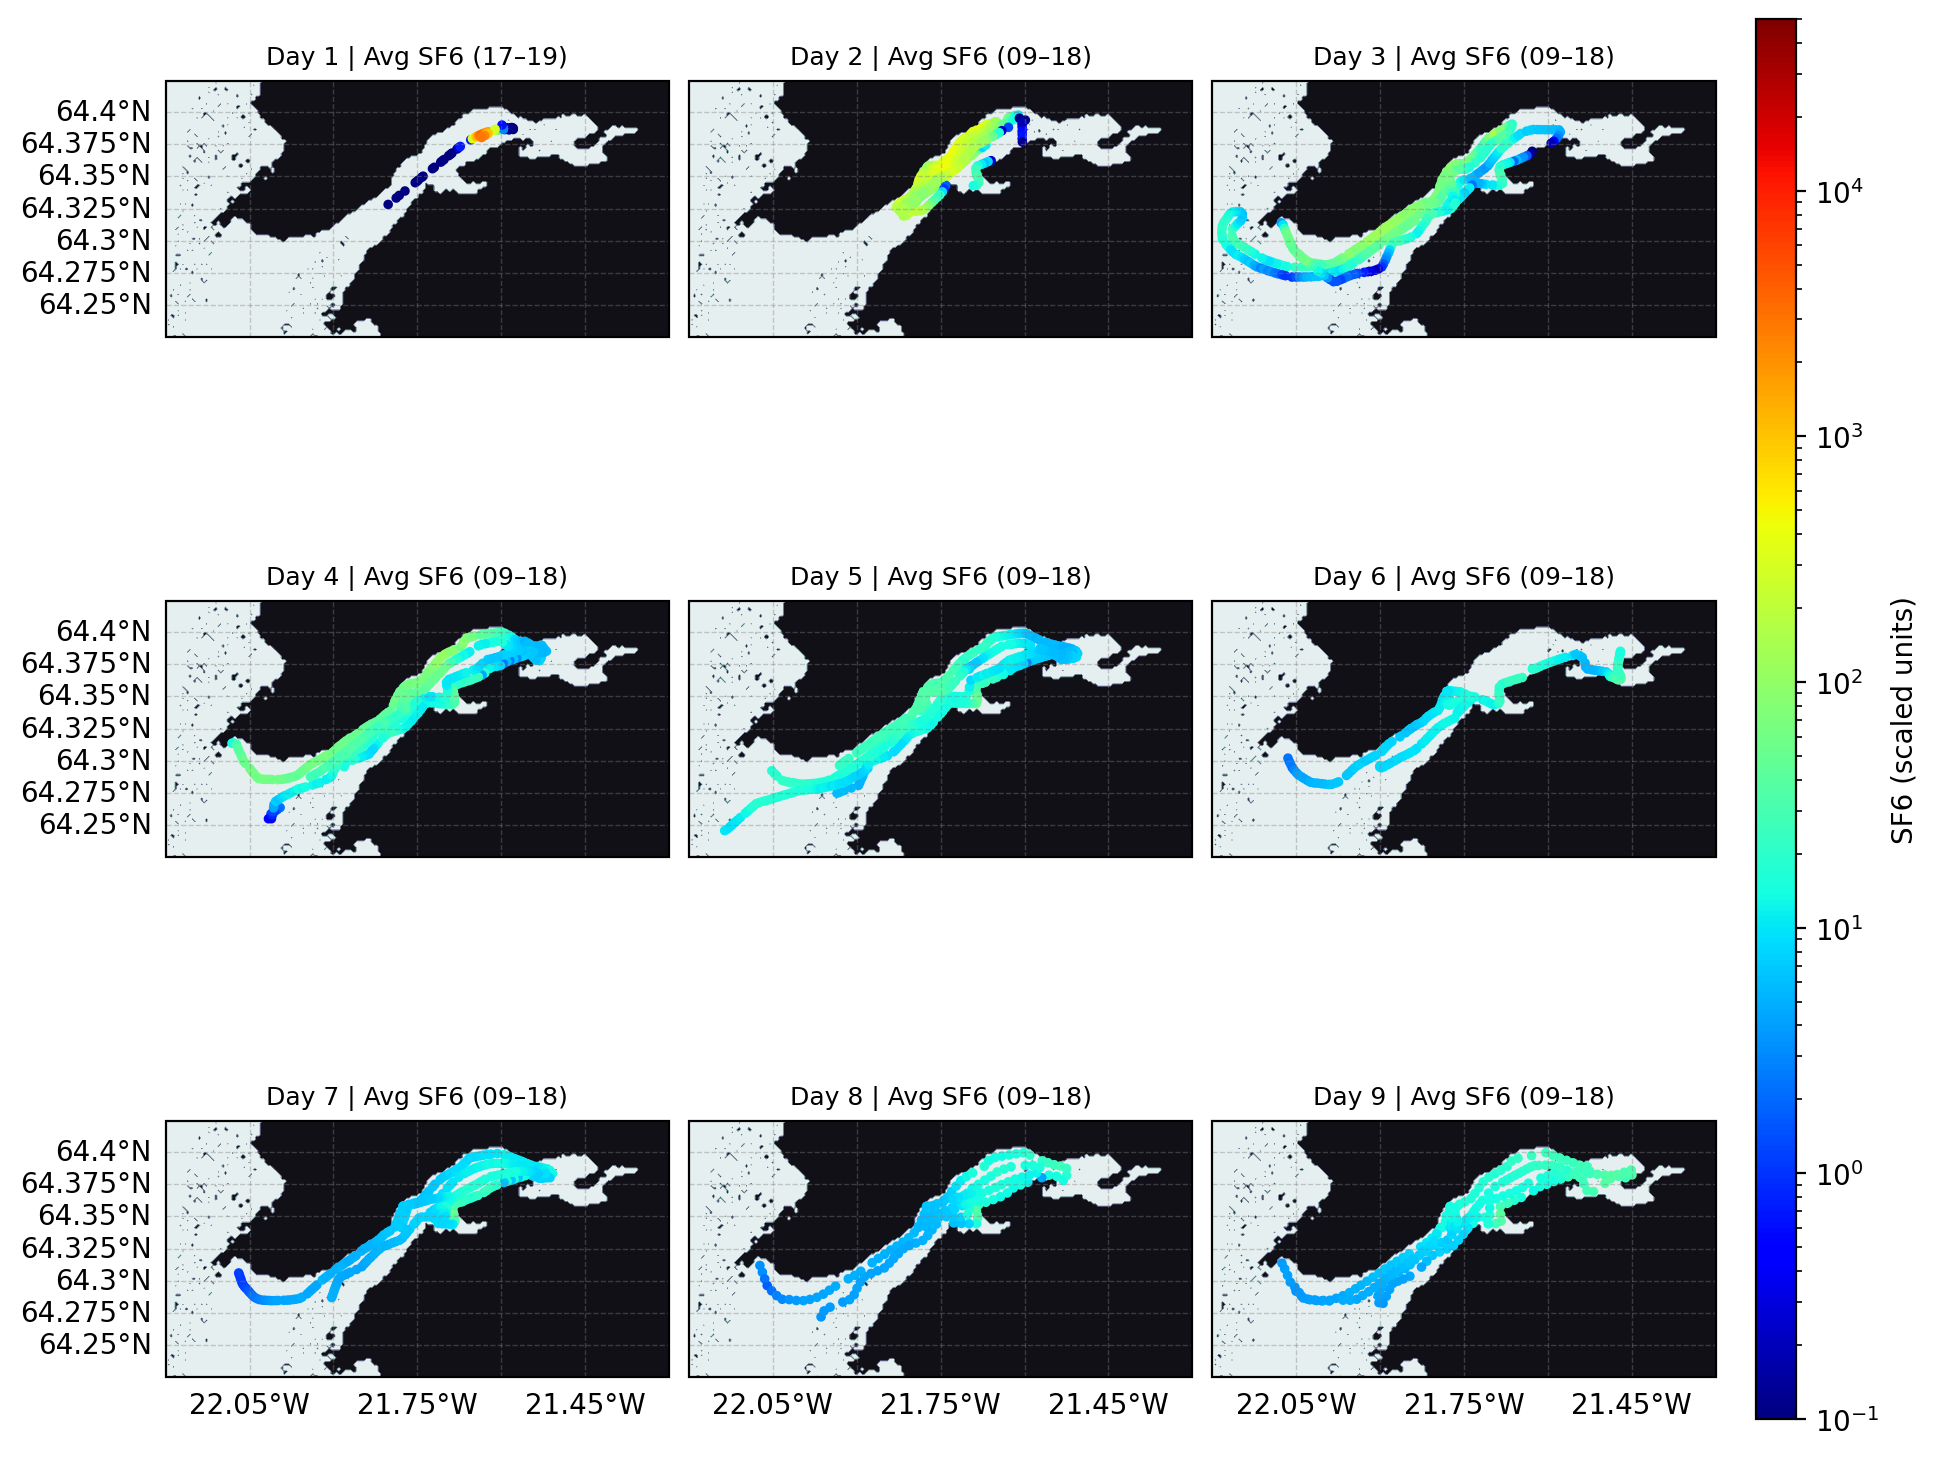

In [14]:
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
scaling_factor=1600

unique_days = np.unique(day_index.values)
num_panels = 9
vmin, vmax = 1e-1, 5e4

fig, axs = plt.subplots(
    nrows=3, ncols=3,
    figsize=(10, 10),
    dpi=200,
    subplot_kw={'projection': ccrs.Mercator()},
    gridspec_kw={'wspace': 0.04, 'hspace': 0.04}
)

axs = axs.flatten()

for d in range(num_panels):

    ax = axs[d]

    if d >= len(unique_days):
        ax.axis('off')
        continue

    day = unique_days[d]
    day_mask = (day_index == day)

    if d == 0:
        hour_mask = (hour_of_day >= 17) & (hour_of_day < 19)
        title_hours = "17–19"
    else:
        hour_mask = (hour_of_day >= 9) & (hour_of_day < 18)
        title_hours = "09–18"

    time_mask = day_mask & hour_mask
    time_idx = np.where(time_mask.values)[0]

    if len(time_idx) == 0:
        ax.axis('off')
        continue

    x_day = (
        x
        .isel(time=time_idx)
        .isel(s_rho=slice(50, 59))
        .mean(dim=['time', 's_rho'])
    )

    dye = roms_regrid(grid, x_day['dye']).load()

    dye_values, lats, lons = [], [], []

    clean_locs = locations_array[d, :, :]
    locations = clean_locs[~np.isnan(clean_locs).any(axis=1)]

    for lat, lon in locations:
        val = (
            dye
            .sel(lat=lat, method='nearest')
            .sel(lon=lon, method='nearest')
            .values
            * scaling_factor
        )
        dye_values.append(val)
        lats.append(lat)
        lons.append(lon)

    # -----------------------
    # Land mask
    # -----------------------
    ax.contourf(
        mask.lon, mask.lat, mask.load(),
        transform=ccrs.PlateCarree(),
        cmap='bone'
    )

    sc = ax.scatter(
        lons, lats,
        c=dye_values,
        cmap='jet',
        s=6,
        norm=LogNorm(vmin=vmin, vmax=vmax),
        transform=ccrs.PlateCarree()
    )

    ax.set_extent(
        [-22.2, -21.3, 64.225, 64.424],
        crs=ccrs.PlateCarree()
    )

    # -----------------------
    # Clean gridlines
    # -----------------------
    gl = ax.gridlines(draw_labels=False,
                      linewidth=0.5,
                      color='gray',
                      alpha=0.4,
                      linestyle='--')

    # Left column latitude labels
    if d % 3 == 0:
        gl.left_labels = True
        gl.yformatter = LATITUDE_FORMATTER

    # Bottom row longitude labels
    if d >= 6:
        gl.bottom_labels = True
        gl.xformatter = LONGITUDE_FORMATTER

    ax.set_title(f"Day {d+1} | Avg SF6 ({title_hours})", fontsize=9)

# -----------------------
# Dedicated colorbar axis
# -----------------------
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label('SF6 (scaled units)')

plt.show()


## Figure panel b: modelled SF₆ along the fjord

For days 1–7 the model dye is sampled at the observed positions as above, averaged in 0.005° longitude bins, and summarised by the median longitude weighted by the binned values (interpolated where the normalised cumulative sum reaches 0.5). Both cells set `scaling_factor = 97.09` and apply it to the regridded dye field and again to the sampled values. The first cell is the final figure (panel b), laid out like panel a in `sf6_observations.ipynb` with grey lines at the fjord mouth and injection longitudes; the second is an earlier variant with longitudes in 0–360 °E, no fixed y-axis limit and no reference lines.

/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve t

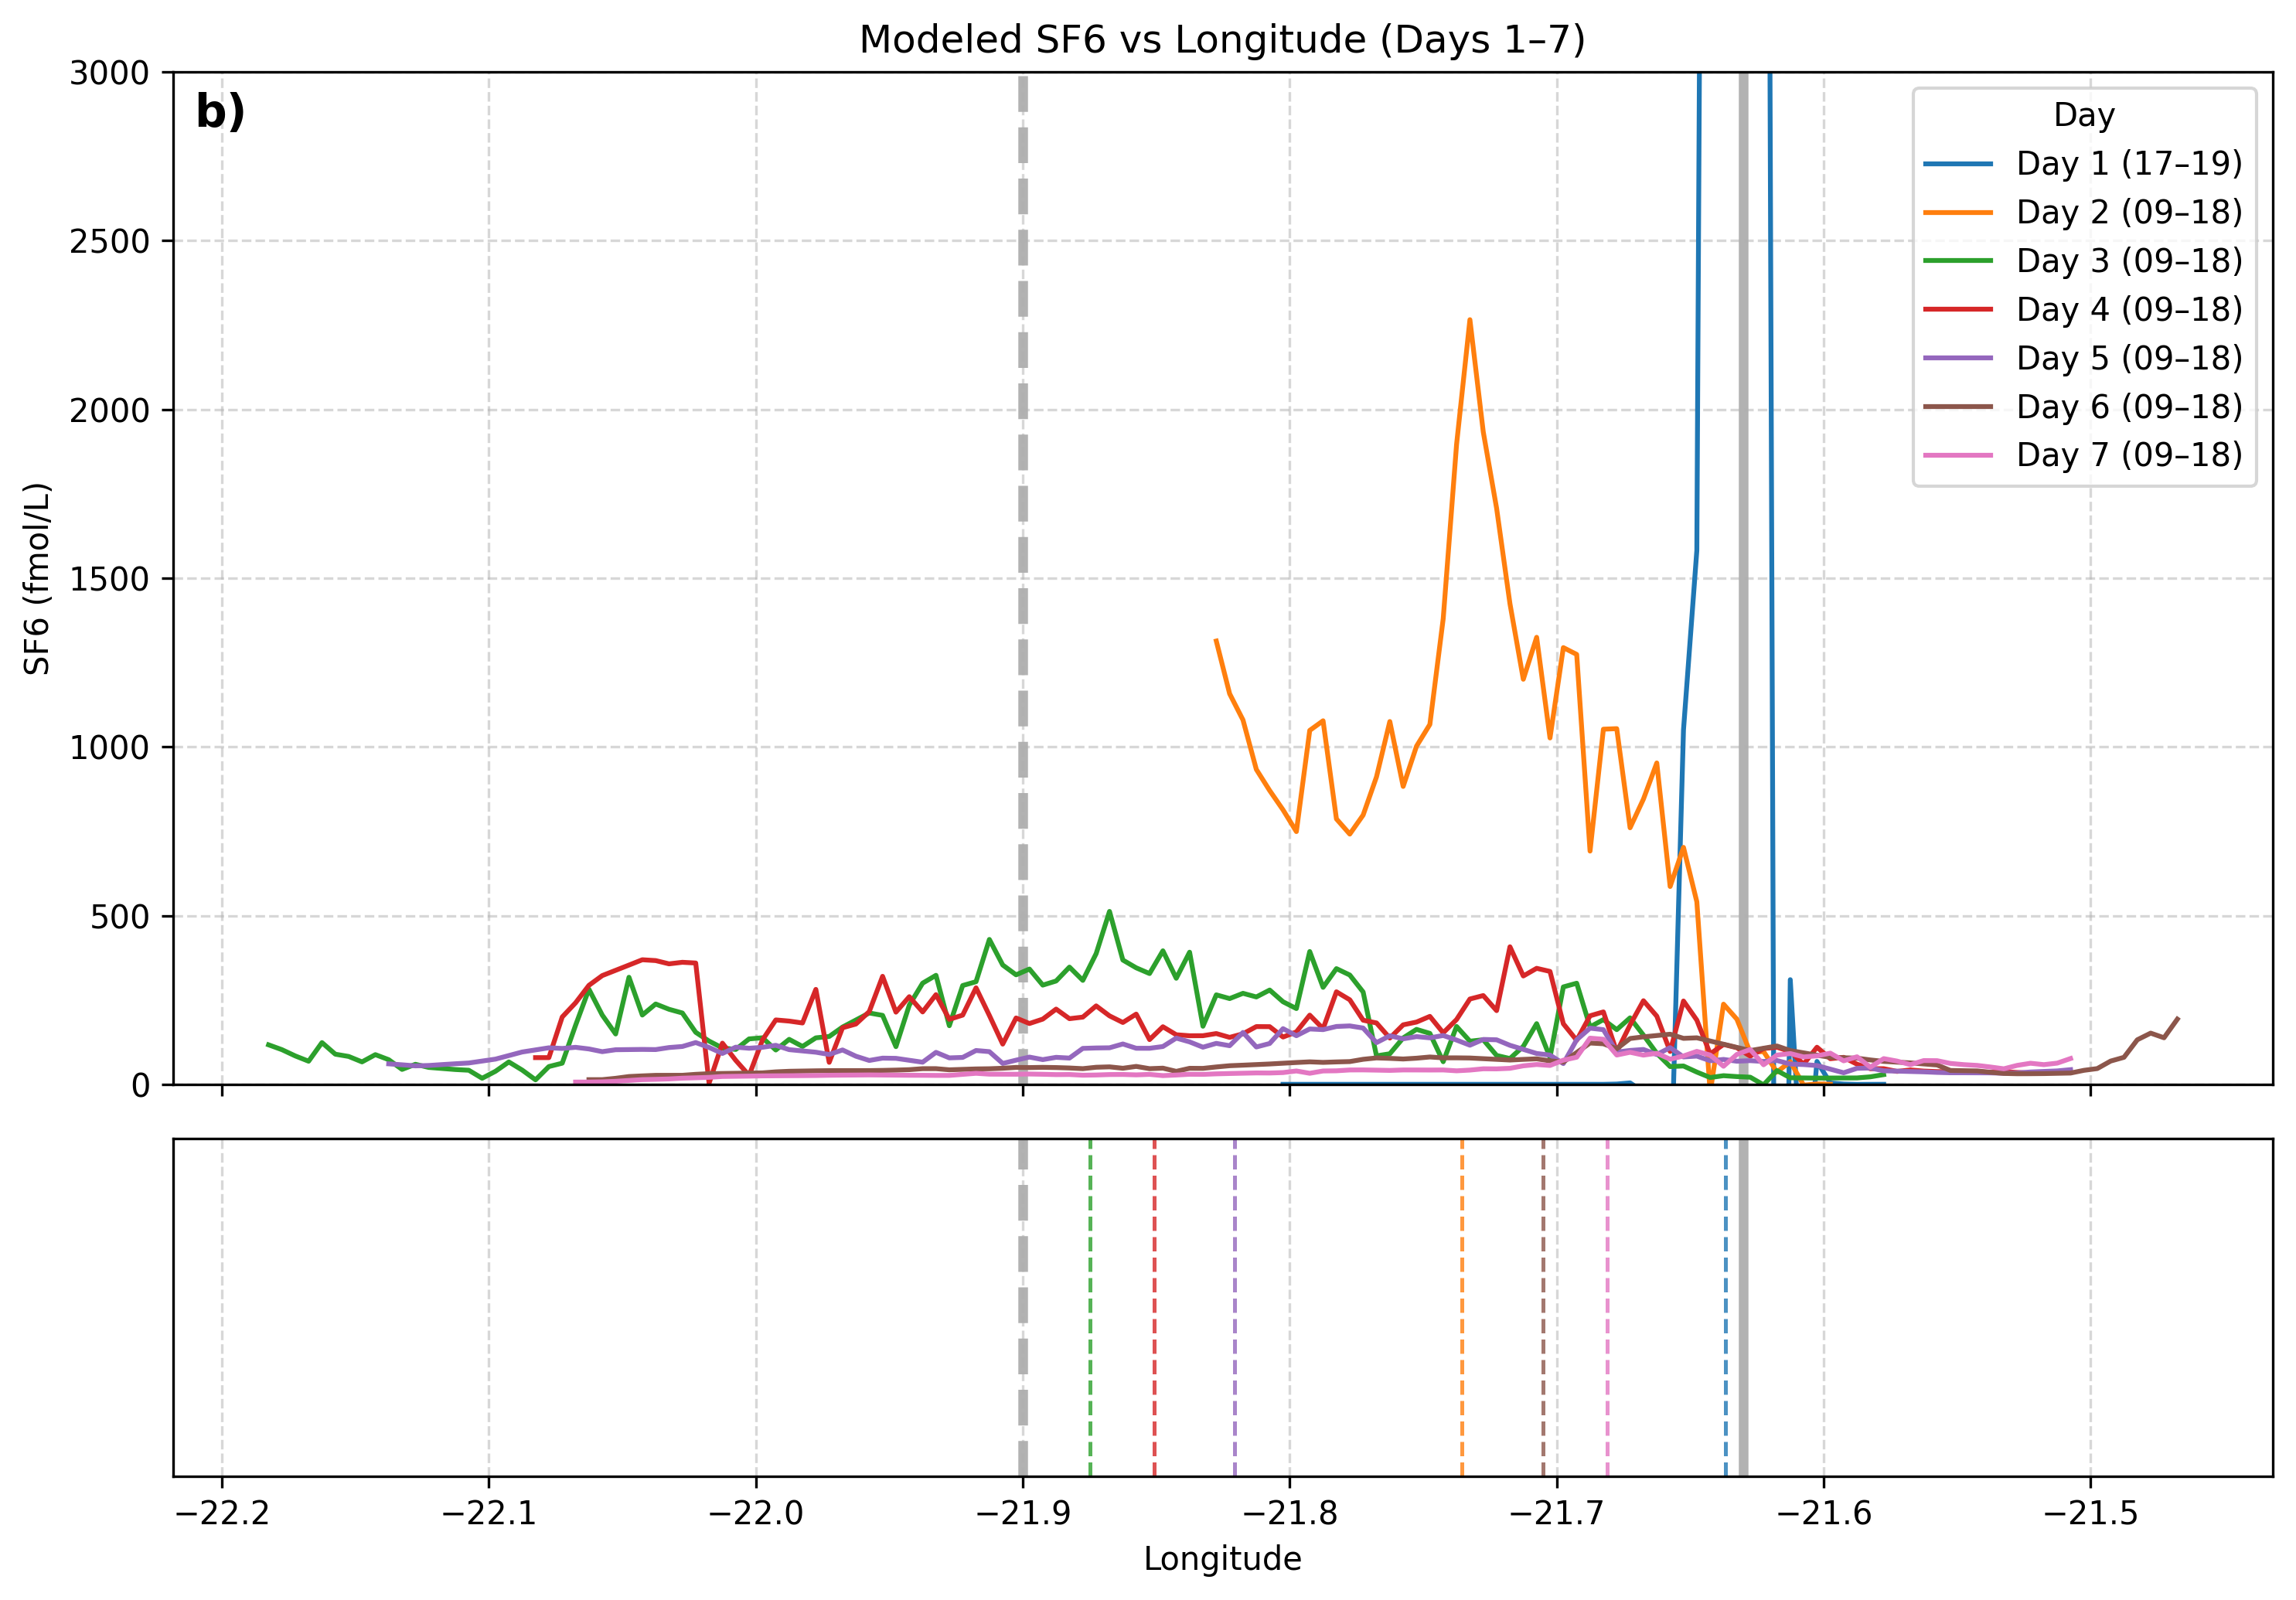

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
scaling_factor=97.09

x = xr.open_mfdataset(
    '/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/Iceland2_MARBL_2024_his.202407????????.nc',
    combine='nested',
    concat_dim=["time"]
)

# open grid
grid = xr.open_mfdataset(
    '/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/P_INPUT/Iceland2_grid.nc'
)

# Constants
hours_per_day = 24
num_days = 7
mouth_lon=-21.9
inj_lon=-21.63

# Precompute the mask
mask = roms_regrid(grid, grid['mask_rho'])

# Set up plotting
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(10, 7), dpi=300, 
                               sharex=True, gridspec_kw={'height_ratios': [3, 1]})
vmin, vmax = 1e-1, 5e4

for d, day in enumerate(unique_days[:num_days]):

    # -----------------------
    # Time masks
    # -----------------------
    day_mask = (day_index == day)

    if d == 0:
        hour_mask = (hour_of_day >= 17) & (hour_of_day < 19)
        label = "Day 1"
    else:
        hour_mask = (hour_of_day >= 9) & (hour_of_day < 18)
        label = f"Day {d+1}"

    time_mask = day_mask & hour_mask

    # ✅ Convert boolean mask → integer indices
    time_idx = np.where(time_mask.values)[0]

    if len(time_idx) == 0:
        continue

    # -----------------------
    # Average over time + depth
    # -----------------------
    x_day = (
        x
        .isel(time=time_idx)
        .isel(s_rho=slice(50, 59))
        .mean(dim=['time', 's_rho'])
    )

    dye = roms_regrid(grid, x_day['dye']).load()
    dye=dye*scaling_factor
    # -----------------------
    # Extract locations
    # -----------------------
    clean_locs = locations_array[d, :, :]
    locations = clean_locs[~np.isnan(clean_locs).any(axis=1)]

    dye_values = []
    lons = []

    for lat, lon in locations:
        val = (
            dye
            .sel(lat=lat, method='nearest')
            .sel(lon=lon, method='nearest')
            .values
            * scaling_factor
        )
        dye_values.append(val)
        lons.append(lon)

    lons = np.array(lons) - 360
    dye_values = np.array(dye_values)

    # -----------------------
    # Bin longitudes (0.05°)
    # -----------------------
    bin_width = 0.005
    lon_min = np.floor(lons.min() / bin_width) * bin_width
    lon_max = np.ceil(lons.max() / bin_width) * bin_width

    bins = np.arange(lon_min, lon_max + bin_width, bin_width)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    bin_idx = np.digitize(lons, bins) - 1

    dye_binned = np.full(len(bin_centers), np.nan)

    for i in range(len(bin_centers)):
        in_bin = bin_idx == i
        if np.any(in_bin):
            dye_binned[i] = np.nanmean(dye_values[in_bin])

    # -----------------------
    # Remove NaNs
    # -----------------------
    valid = np.isfinite(dye_binned)
    lon_valid = bin_centers[valid]
    dye_valid = dye_binned[valid]

    # -----------------------
    # Compute mass-weighted median longitude
    # -----------------------
    cumulative = np.cumsum(dye_valid)
    cumulative /= cumulative[-1]  # normalize to [0, 1]

    # Longitude where 50% of dye is to the west/east
    lon_median = np.interp(0.5, cumulative, lon_valid)

    # -----------------------
    # Plot main line
    # -----------------------
    line, = ax1.plot(
        lon_valid,
        dye_valid,
        '-',
        linewidth=1.5,
        label=label
    )

    line_color = line.get_color()

    # -----------------------
    # Plot mass-weighted median (same color, dashed)
    # -----------------------
    ax2.axvline(
        lon_median,
        linestyle='--',
        linewidth=1.2,
        color=line_color,
        alpha=0.8
    )


# Bottom Plot (Empty Box with Median Labels)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('')           # Hide ylabel
ax2.set_yticks([])           # Remove y-ticks
ax2.set_yticklabels([])      # Remove y-tick labels
ax2.grid(True, axis='x', linestyle='--', alpha=0.5)

# -----------------------
# Final formatting
# -----------------------
#ax1.set_xlabel('Longitude')
ax1.set_ylabel('SF6 (fmol/L)')
ax1.set_title('Modeled SF6 vs Longitude (Days 1–7)')
ax1.legend(title='Day')
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
ax1.set_ylim([-1,3000])
# Panel label a)
ax1.text(
    0.01, 0.98, "b)",
    transform=ax1.transAxes,
    fontsize=14,
    fontweight="bold",
    va="top",
    ha="left"
)

for ax in [ax1, ax2]:
    ax.axvline(mouth_lon, color='grey', linewidth=3,linestyle='--', alpha=0.6, zorder=0)

for ax in [ax1, ax2]:
    ax.axvline(inj_lon, color='grey', linewidth=3, alpha=0.6, zorder=0)

plt.tight_layout()
plt.show()


/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (172, 172).
  result_var = func(*data_vars)
/home/x-uheede/.local/lib/python3.11/site-packages/xarray/computation/apply_ufunc.py:310: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 9.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve t

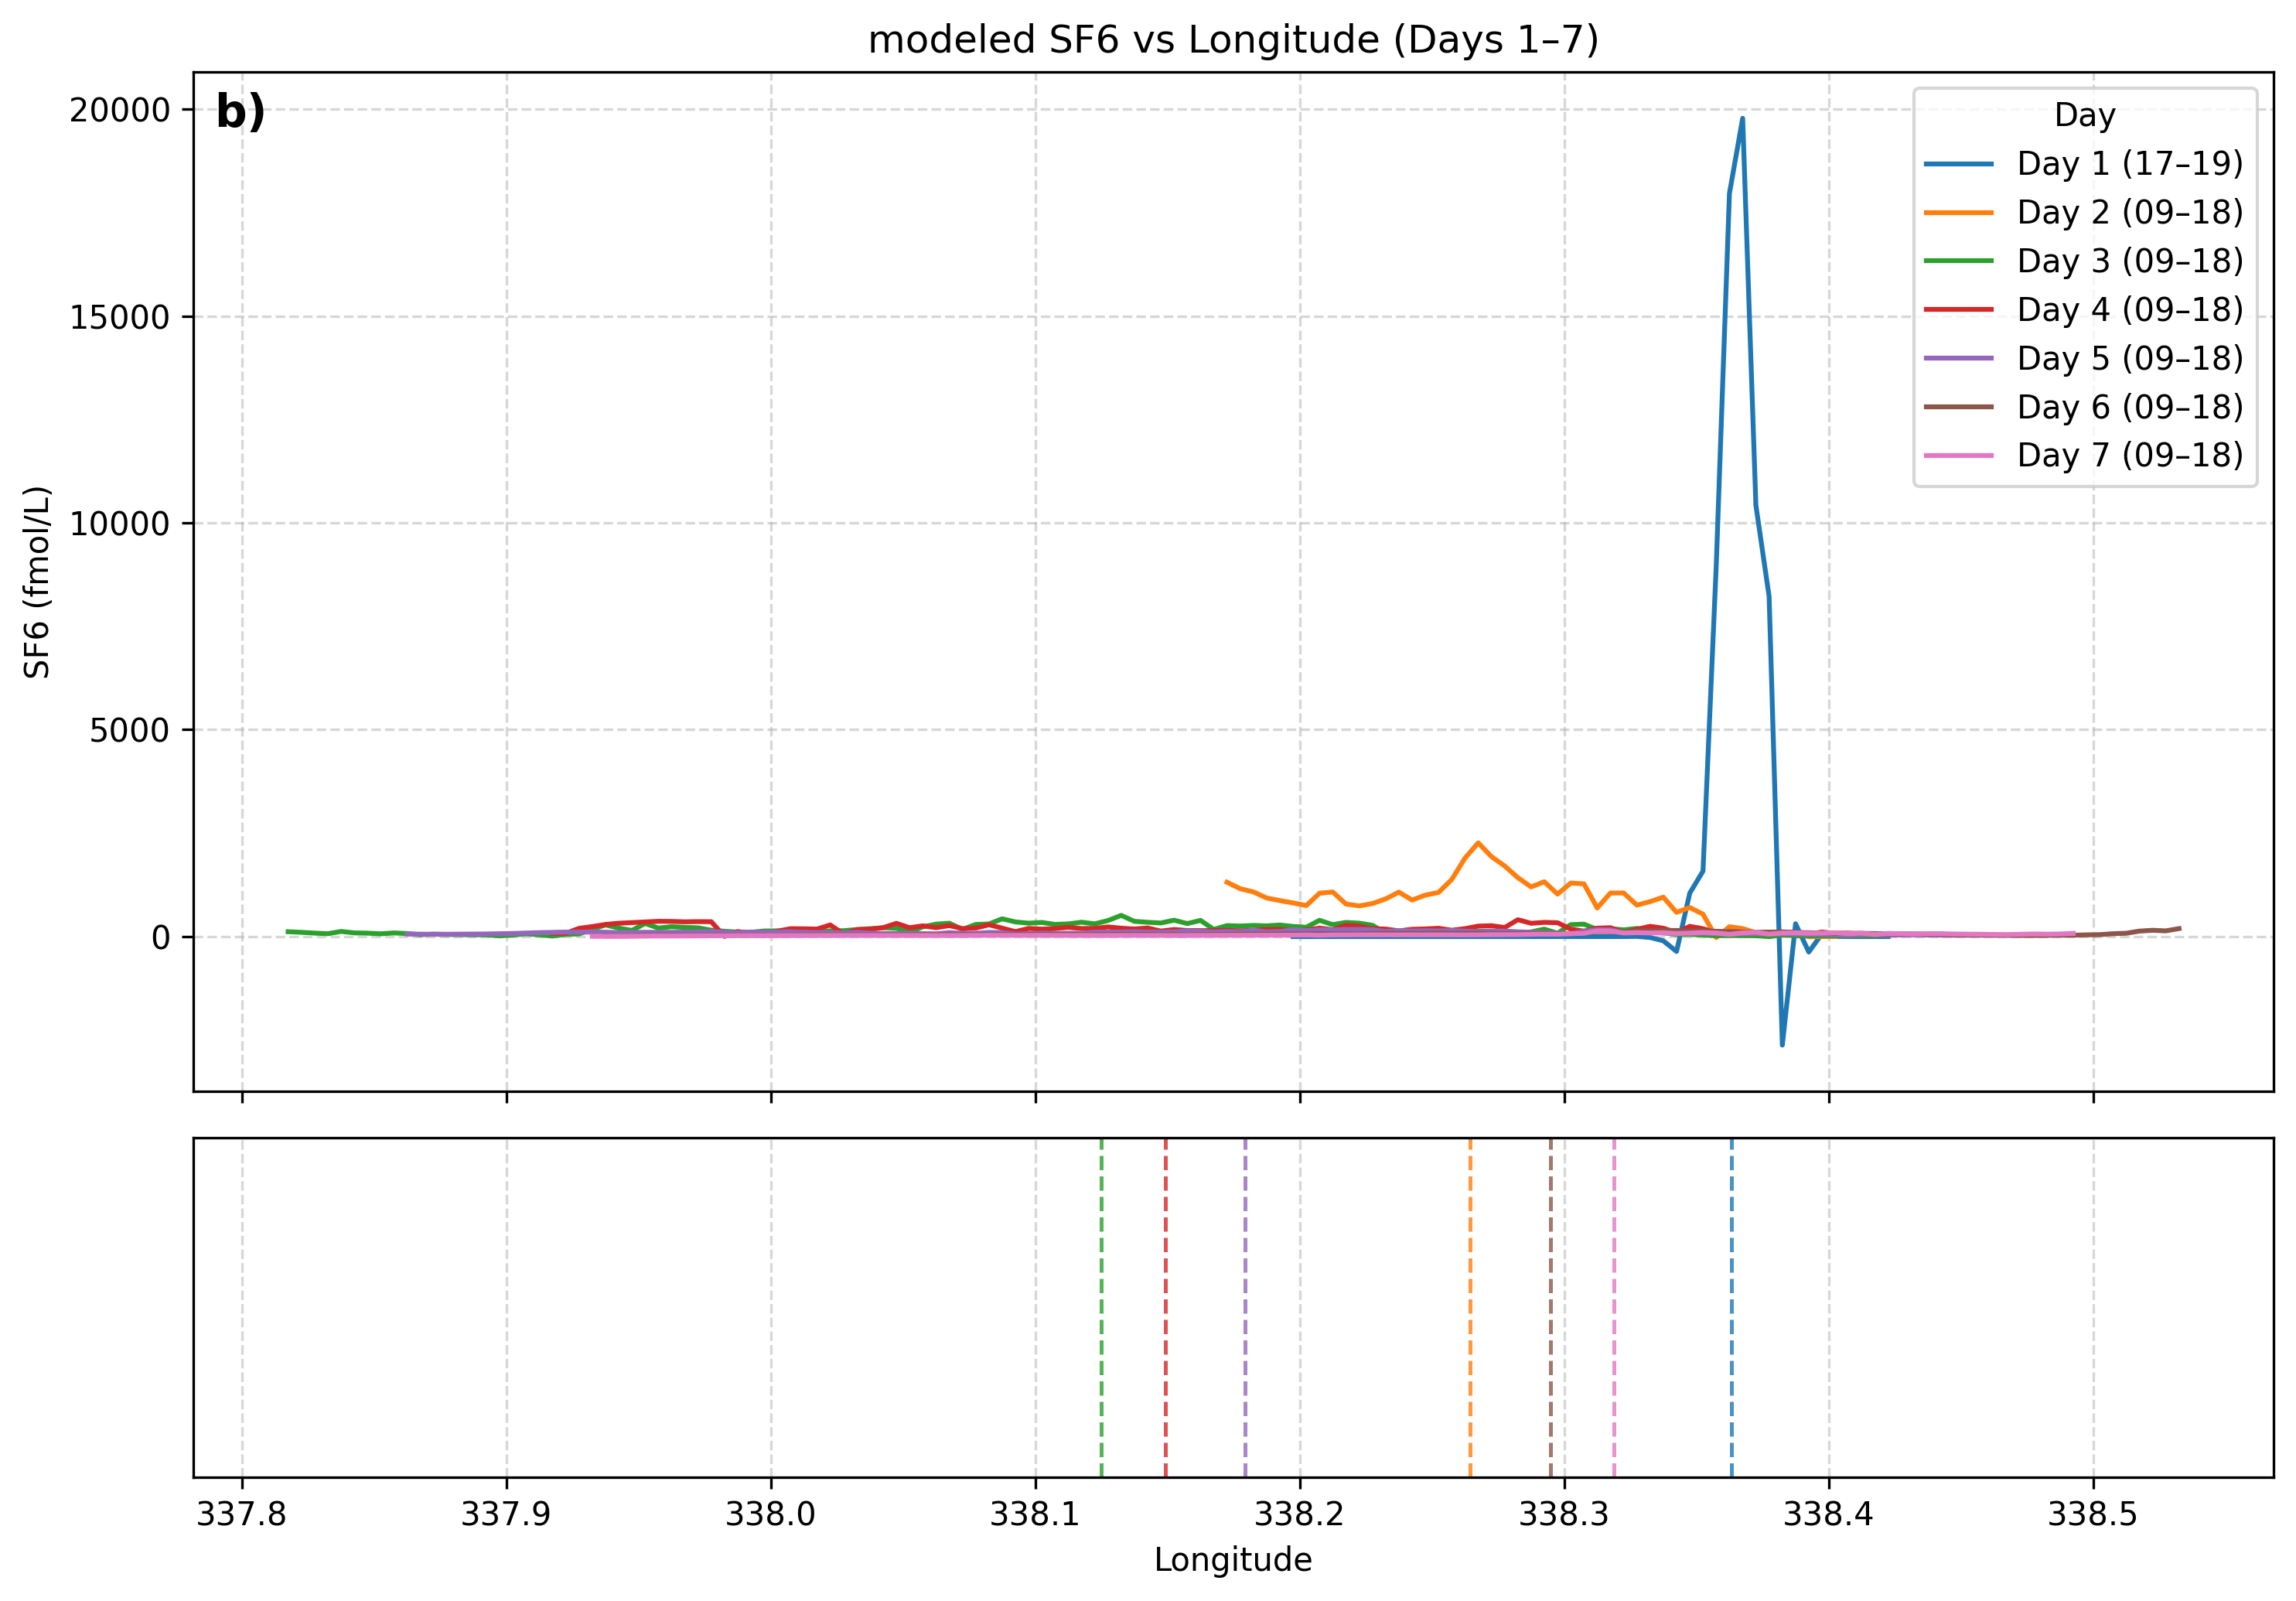

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
scaling_factor=97.09

x = xr.open_mfdataset(
    '/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/Iceland2_MARBL_2024_his.202407????????.nc',
    combine='nested',
    concat_dim=["time"]
)

# open grid
grid = xr.open_mfdataset(
    '/home/x-uheede/S/Iceland2_NOMARBL_2024_DYE_2/P_INPUT/Iceland2_grid.nc'
)

# Constants
hours_per_day = 24
num_days = 7

# Precompute the mask
mask = roms_regrid(grid, grid['mask_rho'])

# Set up plotting
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(10, 7), dpi=300, 
                               sharex=True, gridspec_kw={'height_ratios': [3, 1]})
vmin, vmax = 1e-1, 5e4

for d, day in enumerate(unique_days[:num_days]):

    # -----------------------
    # Time masks
    # -----------------------
    day_mask = (day_index == day)

    if d == 0:
        hour_mask = (hour_of_day >= 17) & (hour_of_day < 19)
        label = "Day 1 (17–19)"
    else:
        hour_mask = (hour_of_day >= 9) & (hour_of_day < 18)
        label = f"Day {d+1} (09–18)"

    time_mask = day_mask & hour_mask

    # ✅ Convert boolean mask → integer indices
    time_idx = np.where(time_mask.values)[0]

    if len(time_idx) == 0:
        continue

    # -----------------------
    # Average over time + depth
    # -----------------------
    x_day = (
        x
        .isel(time=time_idx)
        .isel(s_rho=slice(50, 59))
        .mean(dim=['time', 's_rho'])
    )

    dye = roms_regrid(grid, x_day['dye']).load()
    dye=dye*scaling_factor
    # -----------------------
    # Extract locations
    # -----------------------
    clean_locs = locations_array[d, :, :]
    locations = clean_locs[~np.isnan(clean_locs).any(axis=1)]

    dye_values = []
    lons = []

    for lat, lon in locations:
        val = (
            dye
            .sel(lat=lat, method='nearest')
            .sel(lon=lon, method='nearest')
            .values
            * scaling_factor
        )
        dye_values.append(val)
        lons.append(lon)

    lons = np.array(lons)
    dye_values = np.array(dye_values)

    # -----------------------
    # Bin longitudes (0.05°)
    # -----------------------
    bin_width = 0.005
    lon_min = np.floor(lons.min() / bin_width) * bin_width
    lon_max = np.ceil(lons.max() / bin_width) * bin_width

    bins = np.arange(lon_min, lon_max + bin_width, bin_width)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    bin_idx = np.digitize(lons, bins) - 1

    dye_binned = np.full(len(bin_centers), np.nan)

    for i in range(len(bin_centers)):
        in_bin = bin_idx == i
        if np.any(in_bin):
            dye_binned[i] = np.nanmean(dye_values[in_bin])

    # -----------------------
    # Remove NaNs
    # -----------------------
    valid = np.isfinite(dye_binned)
    lon_valid = bin_centers[valid]
    dye_valid = dye_binned[valid]

    # -----------------------
    # Compute mass-weighted median longitude
    # -----------------------
    cumulative = np.cumsum(dye_valid)
    cumulative /= cumulative[-1]  # normalize to [0, 1]

    # Longitude where 50% of dye is to the west/east
    lon_median = np.interp(0.5, cumulative, lon_valid)

    # -----------------------
    # Plot main line
    # -----------------------
    line, = ax1.plot(
        lon_valid,
        dye_valid,
        '-',
        linewidth=1.5,
        label=label
    )

    line_color = line.get_color()

    # -----------------------
    # Plot mass-weighted median (same color, dashed)
    # -----------------------
    ax2.axvline(
        lon_median,
        linestyle='--',
        linewidth=1.2,
        color=line_color,
        alpha=0.8
    )


# Bottom Plot (Empty Box with Median Labels)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('')           # Hide ylabel
ax2.set_yticks([])           # Remove y-ticks
ax2.set_yticklabels([])      # Remove y-tick labels
ax2.grid(True, axis='x', linestyle='--', alpha=0.5)

# -----------------------
# Final formatting
# -----------------------
#ax1.set_xlabel('Longitude')
ax1.set_ylabel('SF6 (fmol/L)')
ax1.set_title('modeled SF6 vs Longitude (Days 1–7)')
ax1.legend(title='Day')
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
#ax1.set_ylim([-1,3000])
# Panel label a)
ax1.text(
    0.01, 0.98, "b)",
    transform=ax1.transAxes,
    fontsize=14,
    fontweight="bold",
    va="top",
    ha="left"
)
plt.tight_layout()
plt.show()
